# Phenological Rao's Q with TWDTW — *Phenological Diversity Trends with Remote Sensing Datacubes* (BioHackrXiv pqfws, 2024)

**Paper:** E. S. Shayle et al., *Phenological Diversity Trends with Remote Sensing Datacubes*, BioHackrXiv preprint, 2024-06-08, DOI [10.37044/osf.io/pqfws](https://doi.org/10.37044/osf.io/pqfws) (CC BY 4.0; 2024 B-Cubed Hackathon, Group 6).

**Purpose.** Reproduce the paper's central methodological claim on the authors' own worked example: the R package **rasterdiv** was extended with **Time-Weighted Dynamic Time Warping (TWDTW)** so that `paRao()` computes Rao's Q while *accounting for phenology*; the authors report that phenological weighting "can filter out artefacts" compared with non-phenological indices. This notebook runs the authors' pinned vignette example *Computing Multidimensional Rao's Index with and without phenology* — a fully synthetic, self-contained 40×40 grid × 100-step seasonal raster time series — and compares phenological (`dist_m="twdtw"`) vs Euclidean (`dist_m="euclidean"`) Rao's Q maps.

**Scope & status.** Partial demonstration: the synthetic vignette example only. The paper's Calabria Sentinel-2 PPI case study is **not reproducible** (its rasters and in-situ community data were not archived; drone imagery is request-only) and is out of scope. The execution status is stated from the actual outputs of this run in the final cells.

**AI-assisted orchestration notice.** The authors did not provide a Colab notebook. This notebook is **AI-assisted orchestration**: the R code in stages A–C is copied **verbatim from the authors' vignette** (rasterdiv commit `b868c4cf66903d8b5df6a1351f43c287e6c62db1`, GPL ≥ 2, `vignettes/rasterdiv_03_Advanced_multidimension_Rao.Rmd`, rendered at [https://mattmar.github.io/rasterdiv/articles/rasterdiv_03_Advanced_multidimension_Rao.html](https://mattmar.github.io/rasterdiv/articles/rasterdiv_03_Advanced_multidimension_Rao.html)), except four documented adaptations: (1) Python launcher cells write the pinned R source to `/content` and run it with `Rscript` (required because the Colab CLI used for validation executes Python kernels); (2) `np=7` → `np=1` (Colab CPU has 2 vCPUs; the authors' own tests assert `np`-independence) and `rasterOut=FALSE` (plain matrices instead of SpatRasters — identical values, serializable across R processes); (3) result plots use ggplot2 instead of `rasterVis::levelplot`/`gridExtra` (presentation only); (4) a difference map and summary statistics are **added analysis**, explicitly labeled, not a paper figure. Untested behavior of the adaptation is not guaranteed.

日本語: 本ノートブックは、rasterdiv に追加された TWDTW（時間重み付き動的時間歪み）によるフェノロジー考慮型 Rao's Q を、著者自身のビネット例（合成データ・自己完結）で再現します。著者のコードをほぼそのまま使用し、適応箇所（Python ランチャー、`np=1`、プロット方法、追加解析）はすべて明示しています。Calabria の実データ解析はデータ未公開のため対象外です。

## Runtime selection — CPU (no GPU needed)

**Select: `Runtime` → `Change runtime type` → `CPU`.** The method is R + Fortran/C++ (rasterdiv, twdtw); there is no GPU code path anywhere in the computation, so a GPU is neither required nor useful. The full run takes roughly 15–40 minutes (dominated by R package installation; measured times are printed by the cells and reported in the validation record).

日本語: 実行環境は **CPU のみ** で十分です（GPU コードパスなし）。「ランタイム」→「ランタイムのタイプを変更」→「CPU」を選択してください。所要時間の目安はセル出力に表示されます。

### Check the environment

Verifies that the CPU runtime ships R (`/usr/bin/Rscript`) and prints Python/CPU/memory facts actually observed here. Expected: a standard Colab CPU image with R present; the cell fails loudly if R is missing, because everything below depends on it.

日本語: まず R（`/usr/bin/Rscript`）が利用可能か、CPU 数・メモリを確認します。

In [ ]:
import os, shutil, subprocess, platform

print("Python:", platform.python_version(), "| CPUs:", os.cpu_count())
print(subprocess.run(["free", "-h"], capture_output=True, text=True).stdout)
RSCRIPT = shutil.which("Rscript") or "/usr/bin/Rscript"
assert os.path.exists(RSCRIPT), (
    "Rscript not found: select a standard Colab CPU runtime (R is preinstalled there).")
print("Rscript:", RSCRIPT)
ver = subprocess.run([RSCRIPT, "--version"], capture_output=True, text=True)
print((ver.stdout or ver.stderr).strip().splitlines()[0])
os.environ["RUN_OUT"] = "/content/phenorao_out"
os.makedirs(os.environ["RUN_OUT"], exist_ok=True)
print("Output dir:", os.environ["RUN_OUT"])

def run_r(script, timeout):
    # Run an R script and surface its stdout/stderr in this cell's output.
    import sys
    res = subprocess.run(["Rscript", script], capture_output=True, text=True,
                         timeout=timeout)
    if res.stdout:
        print(res.stdout)
    if res.stderr:
        print(res.stderr, file=sys.stderr)
    res.check_returncode()
    return res

Python: 3.13.18 | CPUs: 2
               total        used        free      shared  buff/cache   available
Mem:            12Gi       993Mi       8.8Gi       2.2Mi       3.2Gi        11Gi
Swap:             0B          0B          0B

Rscript: /usr/bin/Rscript
Rscript (R) version 4.6.1 (2026-06-24)
Output dir: /content/phenorao_out


### Install system libraries and R packages

rasterdiv's `Imports` (verified at the pinned commit) are `doParallel, foreach, ggforce, ggplot2, methods, proxy, progress, terra, twdtw, viridis`; the vignette also uses `gstat`. `terra` links against system GDAL/PROJ, `gstat` needs udunits. **Plan A** installs prebuilt Linux binaries from a **date-pinned Posit Package Manager snapshot (2026-10-01, Ubuntu noble)**; **Plan B** falls back to compiling from CRAN if the snapshot is unusable. Expected result: all listed versions printed without error.

日本語: rasterdiv の依存パッケージを、日付固定の Posit バイナリスナップショットから導入します（失敗時は CRAN ソースビルドにフォールバック）。システムライブラリ（GDAL/PROJ など）も先に取得します。

In [ ]:
import subprocess

import subprocess, sys

for cmd in (["apt-get", "update"],
            ["apt-get", "install", "-y",
             "libgdal-dev", "libproj-dev", "libsqlite3-dev", "libudunits2-dev"]):
    res = subprocess.run(cmd, capture_output=True, text=True, timeout=2400)
    for line in (res.stdout or "").strip().splitlines()[-6:]:
        print(line)
    if res.returncode != 0:
        print(res.stderr[-2000:], file=sys.stderr)
        res.check_returncode()
print("system libraries OK")

Get:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble/main amd64 Packages [60.0 kB]
Get:10 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:11 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.5 MB]
Get:12 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,089 kB]
Fetched 13.8 MB in 15s (928 kB/s)
Reading package lists...


libproj-dev is already the newest version (9.4.0-1build2).
libproj-dev set to manually installed.
libsqlite3-dev is already the newest version (3.45.1-1ubuntu2.8).
libsqlite3-dev set to manually installed.
libudunits2-dev is already the newest version (2.2.28-7build1).
0 upgraded, 0 newly installed, 0 to remove and 1 not upgraded.
system libraries OK


Runs the pinned R dependency installation described above (Plan A binaries, Plan B source fallback) and prints the installed versions. Expected: no error, ten version lines.

日本語: 上記の固定スナップショットから依存Rパッケージを導入し、バージョンを表示します。

In [ ]:
from pathlib import Path

Path("/content/phenorao_install_deps.R").write_text(r"""
options(timeout = 600)
options(HTTPUserAgent = sprintf("R/%s R (%s)", getRversion(),
        paste(getRversion(), R.version["platform"], R.version["arch"], R.version["os"])))
pkgs <- c("terra","gstat","proxy","twdtw","doParallel","foreach",
          "progress","viridis","ggplot2","ggforce")
repo_bin <- "https://packagemanager.posit.co/cran/__linux__/noble/2026-10-01"
ok <- tryCatch({
  install.packages(pkgs, repos = repo_bin)
  vapply(pkgs, requireNamespace, logical(1), quietly = TRUE)
}, error = function(e) {
  cat("Binary repo failed:", conditionMessage(e), "\n")
  rep(FALSE, length(pkgs))
})
if (!all(ok)) {
  cat("Falling back to CRAN source compile for:", paste(pkgs[!ok], collapse = ", "), "\n")
  install.packages(pkgs[!ok], repos = "https://cloud.r-project.org")
}
stopifnot(all(vapply(pkgs, requireNamespace, logical(1), quietly = TRUE)))
ip <- installed.packages()[pkgs, "Version"]
for (p in names(ip)) cat(p, as.character(ip[[p]]), "\n")
""")
run_r("/content/phenorao_install_deps.R", 3600)

terra 1.9-50 
gstat 2.1-6 
proxy 0.4-29 
twdtw 1.0-1 
doParallel 1.0.17 
foreach 1.5.2 
progress 1.2.3 
viridis 0.6.5 
ggplot2 4.0.3 
ggforce 0.5.0 



Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
also installing the dependencies ‘e1071’, ‘wk’, ‘classInt’, ‘s2’, ‘units’, ‘xts’, ‘intervals’, ‘abind’, ‘sp’, ‘zoo’, ‘sf’, ‘sftime’, ‘spacetime’, ‘stars’, ‘FNN’, ‘iterators’, ‘gridExtra’, ‘tweenr’, ‘polyclip’

trying URL 'https://packagemanager.posit.co/cran/__linux__/noble/2026-10-01/src/contrib/e1071_1.7-17.tar.gz'
trying URL 'https://packagemanager.posit.co/cran/__linux__/noble/2026-10-01/src/contrib/wk_0.9.5.tar.gz'
trying URL 'https://packagemanager.posit.co/cran/__linux__/noble/2026-10-01/src/contrib/classInt_0.4-11.tar.gz'
trying URL 'https://packagemanager.posit.co/cran/__linux__/noble/2026-10-01/src/contrib/s2_1.1.13.tar.gz'
trying URL 'https://packagemanager.posit.co/cran/__linux__/noble/2026-10-01/src/contrib/units_1.0-1.tar.gz'
trying URL 'https://packagemanager.posit.co/cran/__linux__/noble/2026-10-01/src/contrib/xts_0.14.3.tar.gz'
trying URL 'https://packagemanager.posit.co/cran/__linux__/n

CompletedProcess(args=['Rscript', '/content/phenorao_install_deps.R'], returncode=0, stdout='terra 1.9-50 \ngstat 2.1-6 \nproxy 0.4-29 \ntwdtw 1.0-1 \ndoParallel 1.0.17 \nforeach 1.5.2 \nprogress 1.2.3 \nviridis 0.6.5 \nggplot2 4.0.3 \nggforce 0.5.0 \n', stderr="Installing packages into ‘/usr/local/lib/R/site-library’\n(as ‘lib’ is unspecified)\nalso installing the dependencies ‘e1071’, ‘wk’, ‘classInt’, ‘s2’, ‘units’, ‘xts’, ‘intervals’, ‘abind’, ‘sp’, ‘zoo’, ‘sf’, ‘sftime’, ‘spacetime’, ‘stars’, ‘FNN’, ‘iterators’, ‘gridExtra’, ‘tweenr’, ‘polyclip’\n\ntrying URL 'https://packagemanager.posit.co/cran/__linux__/noble/2026-10-01/src/contrib/e1071_1.7-17.tar.gz'\ntrying URL 'https://packagemanager.posit.co/cran/__linux__/noble/2026-10-01/src/contrib/wk_0.9.5.tar.gz'\ntrying URL 'https://packagemanager.posit.co/cran/__linux__/noble/2026-10-01/src/contrib/classInt_0.4-11.tar.gz'\ntrying URL 'https://packagemanager.posit.co/cran/__linux__/noble/2026-10-01/src/contrib/s2_1.1.13.tar.gz'\ntryi

### Pin the paper-era rasterdiv (v0.3.6)

The paper's method is the TWDTW-enabled `paRao()` of rasterdiv v0.3.6 (commit `b868c4cf66903d8b5df6a1351f43c287e6c62db1`). The current CRAN release (0.3.8) is newer, so this cell installs **exactly rasterdiv 0.3.6 from the pinned CRAN Archive tarball** (pure-R package, quick source install) and asserts the installed version. Expected: `rasterdiv 0.3.6 loaded`.

日本語: 論文時点の rasterdiv 0.3.6 を、CRAN Archive の固定 tarball から導入し、バージョンを検証します。

In [ ]:
from pathlib import Path

Path("/content/phenorao_install_rasterdiv.R").write_text(r"""
# Paper-era rasterdiv (v0.3.6, commit b868c4cf) from the pinned CRAN Archive
# tarball. The package is pure R (no compiled code), so source install is quick.
url <- "https://cran.r-project.org/src/contrib/Archive/rasterdiv/rasterdiv_0.3.6.tar.gz"
install.packages(url, repos = NULL, type = "source")
stopifnot(packageVersion("rasterdiv") == "0.3.6")
suppressPackageStartupMessages(library(rasterdiv))
cat("rasterdiv", as.character(packageVersion("rasterdiv")), "loaded\n")
""")
run_r("/content/phenorao_install_rasterdiv.R", 1800)

rasterdiv 0.3.6 loaded



Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cran.r-project.org/src/contrib/Archive/rasterdiv/rasterdiv_0.3.6.tar.gz'
Content type 'application/x-gzip' length 3527290 bytes (3.4 MB)
downloaded 3.4 MB

* installing *source* package ‘rasterdiv’ ...
** this is package ‘rasterdiv’ version ‘0.3.6’
** package ‘rasterdiv’ successfully unpacked and MD5 sums checked
** using staged installation
** R
** inst
** byte-compile and prepare package for lazy loading
** help
*** installing help indices
** building package indices
** installing vignettes
** testing if installed package can be loaded from temporary location
** testing if installed package can be loaded from final location
** testing if installed package keeps a record of temporary installation path
* DONE (rasterdiv)



CompletedProcess(args=['Rscript', '/content/phenorao_install_rasterdiv.R'], returncode=0, stdout='rasterdiv 0.3.6 loaded\n', stderr="Installing package into ‘/usr/local/lib/R/site-library’\n(as ‘lib’ is unspecified)\ntrying URL 'https://cran.r-project.org/src/contrib/Archive/rasterdiv/rasterdiv_0.3.6.tar.gz'\nContent type 'application/x-gzip' length 3527290 bytes (3.4 MB)\n==================================================\ndownloaded 3.4 MB\n\n* installing *source* package ‘rasterdiv’ ...\n** this is package ‘rasterdiv’ version ‘0.3.6’\n** package ‘rasterdiv’ successfully unpacked and MD5 sums checked\n** using staged installation\n** R\n** inst\n** byte-compile and prepare package for lazy loading\n** help\n*** installing help indices\n** building package indices\n** installing vignettes\n** testing if installed package can be loaded from temporary location\n** testing if installed package can be loaded from final location\n** testing if installed package keeps a record of temporary 

## Stage A — minimal input (authors' synthetic example, no external data)

The example needs **no download**: it generates its own inputs with fixed seeds. Exactly as in the pinned vignette: a spatially autocorrelated 40×40 initial field (gstat variogram simulation, `set.seed(123)`), then a 100-step seasonal time series (amplitude 10) in which an 11×11 central block is deliberately **non-seasonal** (amplitude 5) — the analogue of artificial land cover lacking phenology, the phenomenon the paper's TWDTW weighting is meant to expose. The input array is saved as an RDS for the following stages.

日本語: Stage A では、著者のビネットどおりに固定シードで 40×40×100 の季節ラスタ時系列を生成します（中央 11×11 は意図的に非季節）。外部データは不要です。

In [ ]:
from pathlib import Path

Path("/content/phenorao_simulate.R").write_text(r"""
# ---- Stage A: input simulation (author vignette, verbatim; rasterdiv b868c4cf) ----
library(terra)
library(gstat)

out_dir <- Sys.getenv("RUN_OUT")

gridDim <- 40
xy <- expand.grid(x=1:gridDim, y=1:gridDim)

# Spatially autocorrelated initial field (vignette chunk 7)
varioMod <- vgm(psill=2, range=20, model='Exp')
zDummy <- gstat(formula=z~1, locations = ~x+y, dummy=TRUE, beta=1, model=varioMod, nmax=1)
set.seed(123)
initial_spatial_data <- predict(zDummy, newdata=xy, nsim=1)
initial_spatial_matrix <- matrix(as.integer(initial_spatial_data$sim1 * 100), nrow=gridDim, ncol=gridDim)

# Seasonal time series parameters (vignette chunk 8)
t_steps <- 100
s_dims <- c(gridDim, gridDim)
seasonal_amplitude <- 10
seasonal_amplitudeR <- 5
seasonal_frequency <- 2 * pi / t_steps
seasonal_frequencyR <- 2 * pi / t_steps
non_seasonal_mask <- matrix(FALSE, nrow=gridDim, ncol=gridDim)
non_seasonal_mask[15:25, 15:25] <- TRUE  # 11 rows centered in the middle

time_series_data <- array(0, dim=c(s_dims, t_steps))  # vignette chunk 9
initial_spatial_matrix[non_seasonal_mask] <- floor(rnorm(length(initial_spatial_matrix[non_seasonal_mask]), mean(initial_spatial_matrix), sd = 50))
time_series_data[,,1] <- initial_spatial_matrix

for (t in 2:t_steps) {  # vignette chunk 10, verbatim
  for (i in 1:s_dims[1]) {
    for (j in 1:s_dims[2]) {
      if (non_seasonal_mask[i, j]) {
        seasonal_effect <- seasonal_amplitudeR * sin(seasonal_frequencyR * t)
        noise <- rnorm(1, mean = 0, sd = 1)
        time_series_data[i, j, t] <- as.integer(time_series_data[i, j, t - 1] + seasonal_effect + noise)
      } else {
        seasonal_effect <- seasonal_amplitude * sin(seasonal_frequency * t)
        noise <- rnorm(1, mean = 0, sd = 2)
        time_series_data[i, j, t] <- as.integer(time_series_data[i, j, t - 1] + seasonal_effect + noise)
      }
    }
  }
}

utm32N <- "+proj=utm +zone=32 +ellps=WGS84 +datum=WGS84 +units=m +no_defs"  # vignette chunks 3/12
raster_ts <- rast(time_series_data, extent = ext(0, 40, 0, 40), crs=utm32N)  # vignette chunk 11
saveRDS(time_series_data, file.path(out_dir, "time_series_data.rds"))

# Preview of the input time series (vignette chunk 11 plot; set.seed added for a
# reproducible preview; PNG device instead of screen)
set.seed(123)
png(file.path(out_dir, "input_timeseries.png"), width = 900, height = 420, res = 100)
plot(1:t_steps, seq(min(as.matrix(raster_ts)), max(as.matrix(raster_ts)), length.out = t_steps),
     type = 'o', col = 'white', xlab = 'Time Step', ylab = 'Value')
for (cl in sample(ncol(raster_ts), 10)) {
  for (rw in sample(ncol(raster_ts), 10)) {
    pixel_time_series <- time_series_data[rw, cl, ]
    lines(1:t_steps, pixel_time_series, col = rgb(red = 0, green = 0, blue = 1, alpha = 0.3))
  }
}
dev.off()

png(file.path(out_dir, "input_meanmap.png"), width = 620, height = 540, res = 100)
plot(mean(raster_ts), main = "Average index (input, 100 layers)")
dev.off()

cat("Stage A complete:", t_steps, "steps of", gridDim, "x", gridDim, "pixels\n")
""")
run_r("/content/phenorao_simulate.R", 1800)

[using unconditional Gaussian simulation]
null device 
          1 
null device 
          1 
Stage A complete: 100 steps of 40 x 40 pixels



terra 1.9.50



CompletedProcess(args=['Rscript', '/content/phenorao_simulate.R'], returncode=0, stdout='[using unconditional Gaussian simulation]\nnull device \n          1 \nnull device \n          1 \nStage A complete: 100 steps of 40 x 40 pixels\n', stderr='terra 1.9.50\n')

### Preview of the simulated input

The actual inputs consumed by the analysis, plotted with the author's own preview code (10 sampled pixel trajectories; here written to PNG). **Left: input time-series preview; right: mean over the 100 layers.** The central non-seasonal block is visible in the mean map as the smoother region. These are directly observed data generated by the pinned code, not interpretation.

日本語: 生成された入力（100 ステップのピクセル時系列サンプルと平均マップ）を表示します。中央の平滑な領域が非季節ブロックです。

input_timeseries.png


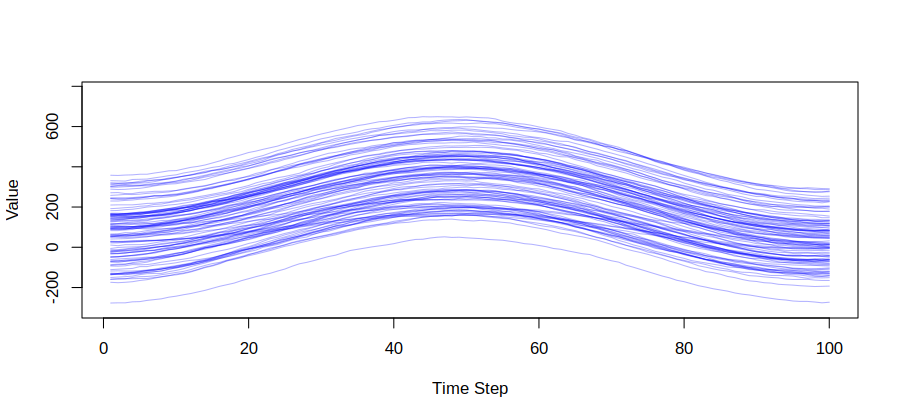

input_meanmap.png


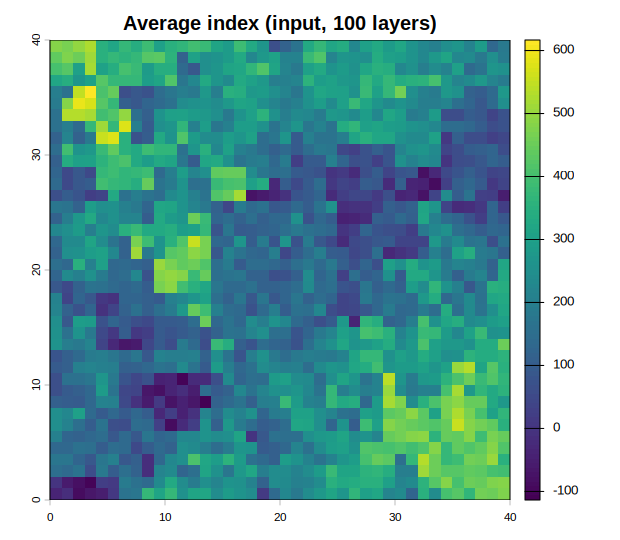

In [ ]:
from IPython.display import Image, display

for name in ("input_timeseries.png", "input_meanmap.png"):
    print(name)
    display(Image(filename=f"/content/phenorao_out/{name}"))

## Stage B — core method: phenological vs Euclidean Rao's Q

Runs the authors' core call (vignette chunk 13): `paRao(x = raster_ts, window = 5, alpha = 2, na.tolerance = 0, method = "multidimension", dist_m = ...)` twice, with two documented adaptations (`np=1`; `rasterOut=FALSE` — plain matrices, identical values, serializable) — once with `time_vector = dates, dist_m = "twdtw"` (phenological; the TWDTW time weighting uses the vignette/`paRao` defaults `stepness = -0.5`, `midpoint = 35`, `cycle_length = "year"`, `time_scale = "day"`, wired through rasterdiv's internal `.mtwdtw` to `twdtw::twdtw`) and once with `dist_m = "euclidean"`. `dates` spans 2023-01-01..2023-12-31 over the 100 layers, exactly as in the vignette. Wall-clock times are printed; the TWDTW run dominates (≈1600 windows × 300 trajectory pairs). The only change is `np=1` (Colab CPU vCPU count; the authors' `tests/testthat/test_paRao.R` asserts `np=1` and `np=2` give identical results).

日本語: Stage B はビネット本体の `paRao()` 呼び出しをそのまま実行します（`np` のみ Colab 向けに 1）。TWDTW 側が計算時間の大半を占めます。

In [ ]:
from pathlib import Path

Path("/content/phenorao_parao.R").write_text(r"""
# ---- Stage B: paRao TWDTW vs euclidean (vignette chunks 12/13; np and
# rasterOut adapted, see notebook text) ----
library(terra)
suppressPackageStartupMessages(library(rasterdiv))

out_dir <- Sys.getenv("RUN_OUT")
time_series_data <- readRDS(file.path(out_dir, "time_series_data.rds"))
utm32N <- "+proj=utm +zone=32 +ellps=WGS84 +datum=WGS84 +units=m +no_defs"
raster_ts <- rast(time_series_data, extent = ext(0, 40, 0, 40), crs = utm32N)

dates <- seq(as.Date("2023-01-01"), as.Date("2023-12-31"), length.out = nlyr(raster_ts))  # vignette chunk 12

t0 <- Sys.time()
RaoPhen <- paRao(x = raster_ts,        # vignette chunk 13; np=7 adapted to np=1
                 window = 5,           # (author tests assert np-independence)
                 alpha = 2,
                 na.tolerance = 0,
                 time_vector = dates,
                 method = "multidimension",
                 dist_m = "twdtw",
                 np = 1, progBar = FALSE,
                 rasterOut = FALSE)  # matrices: identical values to the vignette's
                                     # SpatRaster output, but serializable (SpatRaster
                                     # external pointers cannot cross R processes)
t1 <- Sys.time()
RaoEuc <- paRao(x = raster_ts,
                window = 5,
                alpha = 2,
                na.tolerance = 0,
                method = "multidimension",
                dist_m = "euclidean",
                np = 1, progBar = FALSE,
                rasterOut = FALSE)
t2 <- Sys.time()

saveRDS(RaoPhen, file.path(out_dir, "RaoPhen.rds"))
saveRDS(RaoEuc,  file.path(out_dir, "RaoEuc.rds"))
cat(sprintf("TWDTW Rao wall time: %.1f s\n", as.numeric(t1 - t0, units = "secs")))
cat(sprintf("Euclidean Rao wall time: %.1f s\n", as.numeric(t2 - t1, units = "secs")))
cat("Output list lengths:", length(RaoPhen), length(RaoEuc), "\n")
""")
run_r("/content/phenorao_parao.R", 3600)

TWDTW Rao wall time: 909.7 s
Euclidean Rao wall time: 142.4 s
Output list lengths: 1 1 



terra 1.9.50


Processing alpha: 2 Moving Window: 2
Warning messages:
1: In paRao(x = raster_ts, window = 5, alpha = 2, na.tolerance = 0,  :
  Multidimension Rao's index is experimental and should be used with caution.
2: In paRao(x = raster_ts, window = 5, alpha = 2, na.tolerance = 0,  :
  Simplify=0. Rounding data to 0 decimal places.
3: In paRao(x = raster_ts, window = 5, alpha = 2, na.tolerance = 0,  :
  Input data are float numbers. Converting data to integer matrices.


Processing alpha: 2 Moving Window: 2
Warning messages:
1: In paRao(x = raster_ts, window = 5, alpha = 2, na.tolerance = 0,  :
  Multidimension Rao's index is experimental and should be used with caution.
2: In paRao(x = raster_ts, window = 5, alpha = 2, na.tolerance = 0,  :
  Simplify=0. Rounding data to 0 decimal places.
3: In paRao(x = raster_ts, window = 5, alpha = 2, na.tolerance = 0,  :
  Input data are float numbers. Converting data to integer matrices.



CompletedProcess(args=['Rscript', '/content/phenorao_parao.R'], returncode=0, stdout='TWDTW Rao wall time: 909.7 s\nEuclidean Rao wall time: 142.4 s\nOutput list lengths: 1 1 \n', stderr="terra 1.9.50\n\n\nProcessing alpha: 2 Moving Window: 2\nWarning messages:\n1: In paRao(x = raster_ts, window = 5, alpha = 2, na.tolerance = 0,  :\n  Multidimension Rao's index is experimental and should be used with caution.\n2: In paRao(x = raster_ts, window = 5, alpha = 2, na.tolerance = 0,  :\n  Simplify=0. Rounding data to 0 decimal places.\n3: In paRao(x = raster_ts, window = 5, alpha = 2, na.tolerance = 0,  :\n  Input data are float numbers. Converting data to integer matrices.\n\n\nProcessing alpha: 2 Moving Window: 2\nWarning messages:\n1: In paRao(x = raster_ts, window = 5, alpha = 2, na.tolerance = 0,  :\n  Multidimension Rao's index is experimental and should be used with caution.\n2: In paRao(x = raster_ts, window = 5, alpha = 2, na.tolerance = 0,  :\n  Simplify=0. Rounding data to 0 decim

## Stage C — comparison map (the vignette's result view) and added analysis

Reproduces the vignette's closing comparison view — **average index (input), Rao (euclidean), Phenological Rao (twdtw)** side by side — drawn with ggplot2 `geom_raster` + viridis scales (a presentation-only adaptation of the vignette's `rasterVis::levelplot` view). Stage B returned plain matrices (`rasterOut=FALSE`) because terra `SpatRaster` objects hold external pointers that cannot survive `saveRDS`/`readRDS` across R processes; the values themselves are identical to the vignette's SpatRaster output. Below it, a clearly labeled **notebook-added analysis** (not a paper figure): the difference map `Rao(euclidean) − Rao(twdtw)`, top-5% hotspot overlap, and a summary table contrasting inside vs outside the non-seasonal central block — the paper's abstract claims phenological weighting "filters out artefacts" and helps distinguish areas *lacking* phenological dynamics. These statistics describe this single simulated example only.

日本語: Stage C ではビネットの比較表示を再現し、加えて本ノートブック独自の差分マップ・集計（非季節ブロックの内外比較）を表示します。これらは追加解析であり、論文の図ではありません。

In [ ]:
from pathlib import Path

Path("/content/phenorao_compare.R").write_text(r"""
# ---- Stage C: comparison (vignette chunk 14 content, ggplot2 adaptation) ----
# Stage B returns matrices (rasterOut=FALSE). Their [row, col] layout is
# transposed to raster cell order (row-major), matching terra::values().
library(ggplot2)

out_dir <- Sys.getenv("RUN_OUT")
time_series_data <- readRDS(file.path(out_dir, "time_series_data.rds"))
RaoPhen <- readRDS(file.path(out_dir, "RaoPhen.rds"))
RaoEuc  <- readRDS(file.path(out_dir, "RaoEuc.rds"))

phen_v <- as.vector(t(RaoPhen[[1]][[1]]))   # window.5 / alpha.2
euc_v  <- as.vector(t(RaoEuc[[1]][[1]]))

mean_m <- apply(time_series_data, c(1, 2), mean)
mean_v <- as.vector(t(mean_m))

mk_df <- function(vals, panel) {
  data.frame(col = rep(1:40, times = 40), row = rep(1:40, each = 40),
             value = vals, panel = panel)
}
df <- rbind(mk_df(mean_v, "Average index (input)"),
            mk_df(euc_v,  "Rao (euclidean)"),
            mk_df(phen_v, "Phenological Rao (twdtw)"))
df$y <- 41 - df$row   # matrix row 1 is the top row

p <- ggplot(df, aes(x = col, y = y, fill = value)) +
  geom_raster() +
  scale_fill_viridis_c(na.value = "transparent") +
  facet_wrap(~panel) +
  coord_fixed() +
  labs(x = "Column", y = "Row", fill = "Value",
       caption = "rasterdiv v0.3.6 paRao on the vignette's simulated time series") +
  theme_minimal(12)
ggsave(file.path(out_dir, "comparison_maps.png"), p,
       width = 12, height = 4.5, dpi = 100)

# ---- Notebook-added analysis (not a paper figure) ----
valid <- !is.na(euc_v) & !is.na(phen_v)
ddf <- mk_df(euc_v - phen_v, "Rao(euclidean) - Rao(twdtw)")
ddf$y <- 41 - ddf$row
pd <- ggplot(ddf, aes(x = col, y = y, fill = value)) +
  geom_raster() +
  scale_fill_viridis_c(na.value = "transparent") +
  coord_fixed() +
  labs(x = "Column", y = "Row", fill = "Difference",
       caption = "notebook-added analysis, not a paper figure") +
  theme_minimal(12)
ggsave(file.path(out_dir, "difference_map.png"), pd,
       width = 6.2, height = 5.4, dpi = 100)

in_mask <- (ddf$row %in% 15:25) & (ddf$col %in% 15:25)

stat <- data.frame(
  index = c("Rao_euclidean", "Rao_twdtw"),
  mean = c(mean(euc_v[valid]), mean(phen_v[valid])),
  p95 = c(as.numeric(quantile(euc_v[valid], .95)), as.numeric(quantile(phen_v[valid], .95))),
  mean_inside_noseasonal = c(mean(euc_v[valid & in_mask]), mean(phen_v[valid & in_mask])),
  mean_outside_noseasonal = c(mean(euc_v[valid & !in_mask]), mean(phen_v[valid & !in_mask])),
  row.names = NULL)
stat$contrast_inside_minus_outside <- stat$mean_inside_noseasonal - stat$mean_outside_noseasonal
write.csv(stat, file.path(out_dir, "stats_summary.csv"), row.names = FALSE)

hot_euc <- euc_v[valid] > quantile(euc_v[valid], 0.95)
hot_phen <- phen_v[valid] > quantile(phen_v[valid], 0.95)
cat(sprintf("Valid cells: %d\n", sum(valid)))
cat(sprintf("Euclidean p95 = %.2f; TWDTW p95 = %.2f\n",
            quantile(euc_v[valid], .95), quantile(phen_v[valid], .95)))
cat(sprintf("Top-5%% hotspot cells shared by both indices: %d of %d\n",
            sum(hot_euc & hot_phen), sum(hot_euc)))
cat(sprintf("Pearson corr(euclidean, twdtw): %.3f\n", cor(euc_v[valid], phen_v[valid])))
print(stat)
""")
run_r("/content/phenorao_compare.R", 1800)

Valid cells: 1296
Euclidean p95 = 1977.77; TWDTW p95 = 9876.88
Top-5% hotspot cells shared by both indices: 57 of 65
Pearson corr(euclidean, twdtw): 0.977
          index     mean      p95 mean_inside_noseasonal
1 Rao_euclidean 1201.516 1977.773               1059.995
2     Rao_twdtw 5361.043 9876.878               4981.334
  mean_outside_noseasonal contrast_inside_minus_outside
1                1216.090                     -156.0949
2                5400.145                     -418.8105



CompletedProcess(args=['Rscript', '/content/phenorao_compare.R'], returncode=0, stdout='Valid cells: 1296\nEuclidean p95 = 1977.77; TWDTW p95 = 9876.88\nTop-5% hotspot cells shared by both indices: 57 of 65\nPearson corr(euclidean, twdtw): 0.977\n          index     mean      p95 mean_inside_noseasonal\n1 Rao_euclidean 1201.516 1977.773               1059.995\n2     Rao_twdtw 5361.043 9876.878               4981.334\n  mean_outside_noseasonal contrast_inside_minus_outside\n1                1216.090                     -156.0949\n2                5400.145                     -418.8105\n', stderr='')

Displays the saved comparison view — **average index (input) | Rao (euclidean) | Phenological Rao (twdtw)** — as produced by the cell above. This is the notebook's thumbnail-quality overview of the reproduced result.

日本語: 上のセルが保存した比較図（入力平均｜ユークリッド Rao｜フェノロジー Rao）を表示します。

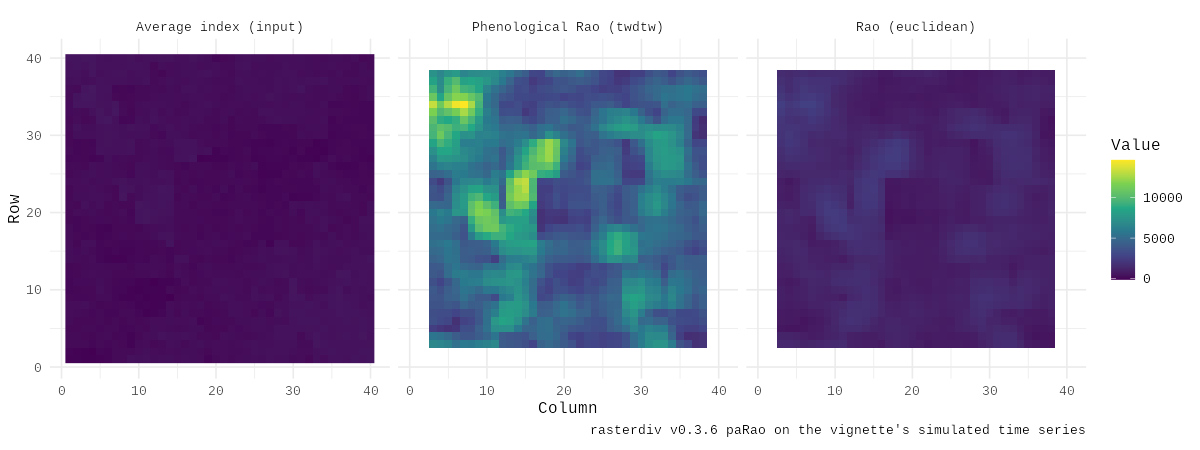

In [ ]:
from IPython.display import Image, display

display(Image(filename="/content/phenorao_out/comparison_maps.png"))

**Notebook-added difference map** (not a paper figure): `Rao(euclidean) − Rao(twdtw)` per cell, for the same valid 36×36 interior. Large positive values mark pixels where plain Euclidean distance — insensitive to season shape — reports much higher local diversity than the phenological index.

日本語: 追加解析の差分マップ（`Rao(ユークリッド) − Rao(TWDTW)`）を表示します。

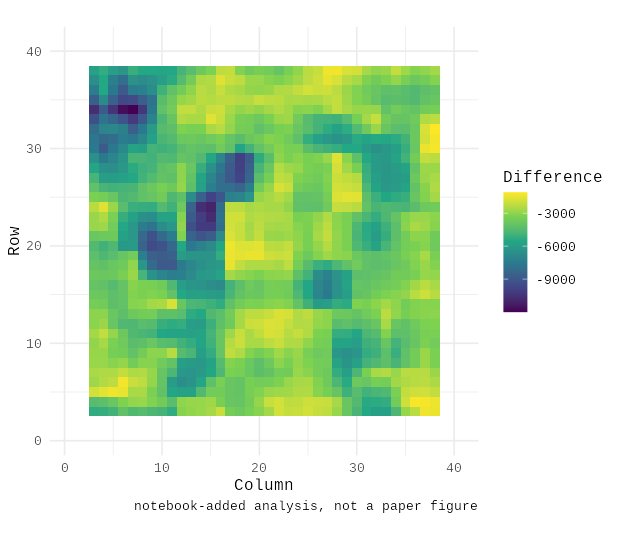

In [ ]:
from IPython.display import Image, display

display(Image(filename="/content/phenorao_out/difference_map.png"))

### Summary statistics (notebook-added, from this single example)

Displays the CSV table written by Stage C (per-index mean, 95th percentile, and the inside-vs-outside contrast for the non-seasonal block) and offers a CSV export. Read alongside the difference map: a large inside-minus-outside contrast for TWDTW relative to Euclidean would support the paper's qualitative claim on this example.

日本語: Stage C が出力した集計表（平均・95%点・非季節ブロック内外のコントラスト）を表示し、CSV として書き出します。

In [ ]:
import pandas as pd

df = pd.read_csv("/content/phenorao_out/stats_summary.csv")
display(df)
df.to_csv("/content/phenorao_stats_export.csv", index=False)
print("CSV export: /content/phenorao_stats_export.csv")

,index,mean,p95,mean_inside_noseasonal,mean_outside_noseasonal,contrast_inside_minus_outside
0,Rao_euclidean,1201.516141,1977.773224,1059.994907,1216.089817,-156.094910
1,Rao_twdtw,5361.043018,9876.877674,4981.334419,5400.144925,-418.810506


CSV export: /content/phenorao_stats_export.csv


## Interpretation, scope and validation record

**How to read the results.** The comparison map reproduces the vignette's central view: Euclidean-distance Rao's Q reacts strongly to the absolute-value differences that the artificial/non-seasonal block accumulates, while the TWDTW phenological Rao weights phenological (shape-of-season) differences. The added table quantifies, for this one simulated example only, how each index contrasts the non-seasonal block against its seasonal surroundings. This single synthetic example **does not** verify the paper's Calabria case-study accuracy figures — that case study is not reproducible (Sentinel-2 PPI rasters and in-situ community data were not archived; drone imagery request-only).

**Validation record.** Filled from the actual outputs above: R and package versions from the install cells; wall-clock timings from Stage B; the `RaoPhen`/`RaoEuc` output structure printed by Stage B; the statistic table from Stage C. All computation ran inside this Colab runtime; no data or weights were downloaded (the example is fully synthetic).

**Differences from the paper.** (1) `np=7` → `np=1` and `rasterOut=FALSE` (results `np`-invariant per authors' tests; matrix container, identical values); (2) plotting via ggplot2; (3) added difference map/statistics (labeled). The TWDTW call path, window, alpha, `na.tolerance`, dates, seeds and simulation code are the authors' own.

**References.** Shayle et al. 2024, BioHackrXiv, DOI 10.37044/osf.io/pqfws (CC BY 4.0). rasterdiv v0.3.6 (GPL ≥ 2), commit `b868c4cf66903d8b5df6a1351f43c287e6c62db1`: `R/paRao.R`, `R/mpaRaoS.R`, `R/mdist.R`, `vignettes/rasterdiv_03_Advanced_multidimension_Rao.Rmd`; author tests `tests/testthat/test_paRao.R` (`np`-independence). twdtw (CRAN 1.0-1), V. Maus et al. — `twdtw::twdtw(x, y, time_weight, cycle_length, time_scale)`. Vignette rendering: https://mattmar.github.io/rasterdiv/articles/rasterdiv_03_Advanced_multidimension_Rao.html.

日本語: 単一の合成例による部分再現であり、論文の Calabria 実データ解析の精度は検証しません。著者コードからの変更点（`np=1`、プロット方法、追加解析）はすべて明示済みです。